In [2]:
!pip install matplotlib-venn


Defaulting to user installation because normal site-packages is not writeable
  Using cached matplotlib-venn-1.1.2.tar.gz (40 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for matplotlib-venn: filename=matplotlib_venn-1.1.2-py3-none-any.whl size=45389 sha256=cbf0b2a0437a411bc50e60206b57de8340bac645ad68a76084f5a9d64de930ed
  Stored in directory: /ihome/alee/rak373/.cache/pip/wheels/c4/16/4a/93374cd955bbe0553a8ce74db7f0fbd5fcc876e19fb78bd601
Successfully built matplotlib-venn


In [1]:
import pandas as pd

# === FILE PATHS ===
dna_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/DNA_SV_df.csv"
rna_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv"

# === LOAD FILES ===
dna_df = pd.read_csv(dna_path)
rna_df = pd.read_csv(rna_path)

# === EXTRACT FUSIONS ===
def extract_fusions(df, column):
    valid = df[column].dropna()
    valid = valid[~valid.isin(["", "not_applicable"])]
    fusions = [fusion.strip() for row in valid for fusion in str(row).split(";") if fusion.strip()]
    return set(fusions)

dna_fusions = extract_fusions(dna_df, "PutativeGeneFusion")
rna_fusions = extract_fusions(rna_df, "RNAFusion")

# === FIND OVERLAP ===
overlap = dna_fusions & rna_fusions

# === OUTPUT ===
print(f"✅ DNA fusion count: {len(dna_fusions)}")
print(f"✅ RNA fusion count: {len(rna_fusions)}")
print(f"🔁 Overlapping fusions: {len(overlap)}\n")

for fusion in sorted(overlap):
    print(f" - {fusion}")

# === OPTIONAL: Save to file in same folder as RNA file ===
import os
overlap_df = pd.DataFrame(sorted(overlap), columns=["OverlappingFusions"])
overlap_path = os.path.join(os.path.dirname(rna_path), "overlapping_fusions.csv")
overlap_df.to_csv(overlap_path, index=False)
print(f"\n💾 Overlapping fusion list saved to: {overlap_path}")


✅ DNA fusion count: 1148
✅ RNA fusion count: 383
🔁 Overlapping fusions: 37

 - AL109615.3-AL583836.1
 - ALCAM-AL136418.1
 - AP2B1-SKAP1
 - APBB2-PTPRR
 - ARHGEF7-ATP11A
 - ATXN2-BRAP
 - BACE2-MX1
 - CDC14A-LSAMP
 - CNOT1-GOT2
 - CTC1-STX8
 - DENND5A-SORL1
 - EDC3-PREX1
 - ESR1-ARNT2
 - ITGAV-GULP1
 - MED13-ABCA6
 - METTL16-BRCA1
 - NFE2L3-CBX3
 - NIPBL-AC034114.2
 - NUP107-OTOGL
 - OXNAD1-PLCL2
 - PCBP1-AS1-PPP1R1B
 - PITPNC1-SDK2
 - PPFIA1-ARHGAP32
 - PPFIBP2-KMT5B
 - PPP2R5E-PIGH
 - PPP3CB-SAFB
 - PRKACB-PAH
 - PVT1-PSIP1
 - RFC1-SMIM14
 - SPHK2-SEC1P
 - SPON2-FBXL5
 - TAB3-DMD
 - TPST1-AC027644.4
 - TPST1-RABGEF1
 - TUSC3-ANO1
 - UNC13B-PLEKHG6
 - UVRAG-MYO7A

💾 Overlapping fusion list saved to: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/overlapping_fusions.csv


In [1]:
import pandas as pd
import os
from collections import Counter

file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion.csv"
delimiter = ","  # Use '\t' if it's a TSV

# === LOAD DATA ===
df = pd.read_csv(file_path, delimiter=delimiter)

# === FILTER AND EXTRACT FUSIONS ===
fusion_col = 'PutativeGeneFusion'

# Drop missing or "not_applicable" values
valid_fusions = df[fusion_col].dropna()
valid_fusions = valid_fusions[~valid_fusions.isin(["", "not_applicable"])]

# Split by semicolon and flatten
fusion_list = [fusion.strip() for row in valid_fusions for fusion in row.split(";") if fusion.strip()]

# Get unique fusions
unique_fusions = sorted(set(fusion_list))

# === DEBUG OUTPUT ===
print(f"Total unique gene fusions: {len(unique_fusions)}\n")
print("Unique fusion types:")
for fusion in unique_fusions:
    print(f" - {fusion}")

# Count frequency of each fusion (including duplicates)
fusion_counter = Counter(fusion_list)

print("\nAll extracted fusions (including duplicates and their counts):\n")
for fusion, count in fusion_counter.items():
    print(f"{fusion}: {count} time(s)")

# Total number of fusion entries (may include duplicates)
print(f"\nTotal gene fusions (including duplicates): {len(fusion_list)}")
print(f"Total unique gene fusions: {len(unique_fusions)}")

# === SAVE TO FILE IN SAME DIRECTORY ===
fusion_df = pd.DataFrame(fusion_counter.items(), columns=["Fusion", "Count"])
output_dir = os.path.dirname(file_path)
output_file = os.path.join(output_dir, "fusion_counts.csv")
fusion_df.to_csv(output_file, index=False)

print(f"\n Saved fusion counts to: {output_file}")


Total unique gene fusions: 1147

Unique fusion types:
 - AATF-HDAC5
 - ABCA13-AC007780.1
 - ABCA13-WIPI1
 - AC000061.1-RNF17
 - AC002070.1-AACS
 - AC002470.2-AC002472.2
 - AC002470.2-THAP7-AS1
 - AC004147.4-JUP
 - AC004702.1-TRIM25
 - AC005019.2-ETV1
 - AC005697.1-LIG3
 - AC005746.2-CACNG4
 - AC005828.1-CYP24A1
 - AC005828.1-KCNH6
 - AC005884.1-AC005856.1
 - AC005884.1-CACNG4
 - AC005899.8-ASIC2
 - AC005906.2-AC006206.2
 - AC006487.1-BRIP1
 - AC006487.2-BRIP1
 - AC006978.2-SUZ12
 - AC007179.2-AC007100.1
 - AC007317.1-LDHAP3
 - AC007317.2-LDHAP3
 - AC007463.2-ENOX1
 - AC007563.2-YES1
 - AC007881.2-MCEE
 - AC008056.1-SYNE3
 - AC008073.3-ITSN2
 - AC008543.1-AC016587.1
 - AC008966.1-LINC02219
 - AC010646.1-ABHD8
 - AC010646.1-MRPL34
 - AC010969.2-GRHL1
 - AC010969.3-GRHL1
 - AC011092.2-AC112694.1
 - AC011246.1-LYPD6B
 - AC011468.5-Y_RNA
 - AC012158.1-AC069228.1
 - AC012158.1-PPFIA2
 - AC012501.2-GALNT13
 - AC013762.1-AP001636.3
 - AC015574.1-NR2F2-AS1
 - AC015687.1-CNBD1
 - AC015845.1-GDPD

In [1]:
import pandas as pd
import os
from collections import Counter

file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion_Tumor.csv"
delimiter = ","  # Use '\t' if it's a TSV

# === LOAD DATA ===
df = pd.read_csv(file_path, delimiter=delimiter)

# === FILTER AND EXTRACT FUSIONS ===
fusion_col = 'PutativeGeneFusion'

# Drop missing or "not_applicable" values
valid_fusions = df[fusion_col].dropna()
valid_fusions = valid_fusions[~valid_fusions.isin(["", "not_applicable"])]

# Split by semicolon and flatten
fusion_list = [fusion.strip() for row in valid_fusions for fusion in row.split(";") if fusion.strip()]

# Get unique fusions
unique_fusions = sorted(set(fusion_list))

# === DEBUG OUTPUT ===
print(f"Total unique gene fusions: {len(unique_fusions)}\n")
print("Unique fusion types:")
for fusion in unique_fusions:
    print(f" - {fusion}")

# Count frequency of each fusion (including duplicates)
fusion_counter = Counter(fusion_list)

print("\nAll extracted fusions (including duplicates and their counts):\n")
for fusion, count in fusion_counter.items():
    print(f"{fusion}: {count} time(s)")

# Total number of fusion entries (may include duplicates)
print(f"\nTotal gene fusions (including duplicates): {len(fusion_list)}")
print(f"Total unique gene fusions: {len(unique_fusions)}")

# === SAVE TO FILE IN SAME DIRECTORY ===
fusion_df = pd.DataFrame(fusion_counter.items(), columns=["Fusion", "Count"])
output_dir = os.path.dirname(file_path)
output_file = os.path.join(output_dir, "fusion_counts_Tumor.csv")
fusion_df.to_csv(output_file, index=False)

print(f"\n Saved fusion counts to: {output_file}")


Total unique gene fusions: 532

Unique fusion types:
 - AATF-HDAC5
 - AC002070.1-AACS
 - AC002470.2-AC002472.2
 - AC002470.2-THAP7-AS1
 - AC004702.1-TRIM25
 - AC005828.1-CYP24A1
 - AC005828.1-KCNH6
 - AC005884.1-AC005856.1
 - AC005906.2-AC006206.2
 - AC006487.1-BRIP1
 - AC006487.2-BRIP1
 - AC007179.2-AC007100.1
 - AC007317.1-LDHAP3
 - AC007317.2-LDHAP3
 - AC007463.2-ENOX1
 - AC007563.2-YES1
 - AC008073.3-ITSN2
 - AC008543.1-AC016587.1
 - AC008966.1-LINC02219
 - AC010646.1-ABHD8
 - AC010646.1-MRPL34
 - AC012158.1-AC069228.1
 - AC012158.1-PPFIA2
 - AC015574.1-NR2F2-AS1
 - AC015687.1-CNBD1
 - AC016582.1-SIPA1L3
 - AC016735.1-THADA
 - AC018437.3-AP002754.2
 - AC021127.1-AC004052.1
 - AC022509.1-MED13L
 - AC022509.2-MED13L
 - AC022509.2-MSRB3
 - AC023137.1-SETD2
 - AC023480.1-AC005220.1
 - AC024022.1-ITPR2
 - AC024145.1-MSRB3
 - AC025419.1-PTPRQ
 - AC026353.1-VWA3A
 - AC027644.4-TMEM248
 - AC053481.2-EFCAB3
 - AC055714.1-RPRD1A
 - AC055811.2-HLF
 - AC068531.1-BRIP1
 - AC073082.1-HIP1
 - AC0

In [2]:
import pandas as pd
import os
from collections import Counter

file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion_IPM.csv"
delimiter = ","  # Use '\t' if it's a TSV

# === LOAD DATA ===
df = pd.read_csv(file_path, delimiter=delimiter)

# === FILTER AND EXTRACT FUSIONS ===
fusion_col = 'PutativeGeneFusion'

# Drop missing or "not_applicable" values
valid_fusions = df[fusion_col].dropna()
valid_fusions = valid_fusions[~valid_fusions.isin(["", "not_applicable"])]

# Split by semicolon and flatten
fusion_list = [fusion.strip() for row in valid_fusions for fusion in row.split(";") if fusion.strip()]

# Get unique fusions
unique_fusions = sorted(set(fusion_list))

# === DEBUG OUTPUT ===
print(f"Total unique gene fusions: {len(unique_fusions)}\n")
print("Unique fusion types:")
for fusion in unique_fusions:
    print(f" - {fusion}")

# Count frequency of each fusion (including duplicates)
fusion_counter = Counter(fusion_list)

print("\nAll extracted fusions (including duplicates and their counts):\n")
for fusion, count in fusion_counter.items():
    print(f"{fusion}: {count} time(s)")

# Total number of fusion entries (may include duplicates)
print(f"\nTotal gene fusions (including duplicates): {len(fusion_list)}")
print(f"Total unique gene fusions: {len(unique_fusions)}")

# === SAVE TO FILE IN SAME DIRECTORY ===
fusion_df = pd.DataFrame(fusion_counter.items(), columns=["Fusion", "Count"])
output_dir = os.path.dirname(file_path)
output_file = os.path.join(output_dir, "fusion_counts_IPM.csv")
fusion_df.to_csv(output_file, index=False)

print(f"\n Saved fusion counts to: {output_file}")


Total unique gene fusions: 618

Unique fusion types:
 - ABCA13-AC007780.1
 - ABCA13-WIPI1
 - AC000061.1-RNF17
 - AC004147.4-JUP
 - AC005019.2-ETV1
 - AC005697.1-LIG3
 - AC005746.2-CACNG4
 - AC005884.1-CACNG4
 - AC005899.8-ASIC2
 - AC006978.2-SUZ12
 - AC007881.2-MCEE
 - AC008056.1-SYNE3
 - AC010969.2-GRHL1
 - AC010969.3-GRHL1
 - AC011092.2-AC112694.1
 - AC011246.1-LYPD6B
 - AC011468.5-Y_RNA
 - AC012501.2-GALNT13
 - AC013762.1-AP001636.3
 - AC015845.1-GDPD1
 - AC016595.1-AC106799.2
 - AC018690.1-EPHA6
 - AC021546.1-ZFPM2
 - AC021613.1-AP000688.1
 - AC021723.2-TENM4
 - AC022509.1-AC087883.2
 - AC022509.2-AC087883.2
 - AC023480.1-SUMF1
 - AC024610.2-JUP
 - AC026167.1-CATSPERB
 - AC026167.1-RCAN2
 - AC034268.2-STXBP4
 - AC034268.2-USP32
 - AC036214.3-OXR1
 - AC044810.2-PRMT3
 - AC044810.3-ARHGAP42
 - AC044810.3-PRMT3
 - AC046195.1-TRAPPC9
 - AC046195.2-TRAPPC9
 - AC058822.1-PPP1R12A
 - AC068442.1-GRAPL
 - AC069368.1-LINC02253
 - AC069368.1-TTC23
 - AC073115.2-PITPNM2
 - AC077690.1-PLCL2
 - 

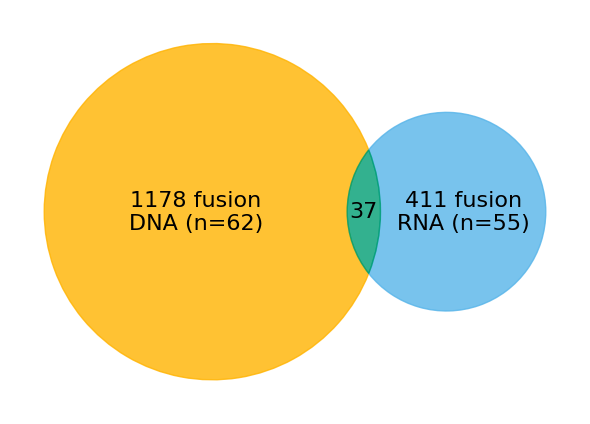

Saved Venn diagram with total fusion counts inside circles at: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/rna_dna_fusions_venn.png


In [4]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import os

# Fusion data
rna_fusions = 411
dna_fusions = 1178
overlap = 37

# Venn subsets (for shape only)
only_rna = rna_fusions - overlap
only_dna = dna_fusions - overlap

# Output path
output_dir = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs"
output_file = os.path.join(output_dir, "rna_dna_fusions_venn.png")

# Create plot
plt.figure(figsize=(6, 6))
venn = venn2(subsets=(only_dna, only_rna, overlap))  # DNA on left, RNA on right

# Set custom colors for regions
venn.get_patch_by_id('10').set_color('#FFB300')   # DNA only - amber
venn.get_patch_by_id('01').set_color('#56B4E9')   # RNA only - light blue
venn.get_patch_by_id('11').set_color('#009E73')   # Overlap - green

# Optional: transparency
venn.get_patch_by_id('10').set_alpha(0.8)
venn.get_patch_by_id('01').set_alpha(0.8)
venn.get_patch_by_id('11').set_alpha(0.8)

# Set custom labels
venn.get_label_by_id('10').set_text(f"{dna_fusions} fusion\nDNA (n=62)")
venn.get_label_by_id('01').set_text(f"{rna_fusions} fusion\nRNA (n=55)")
venn.get_label_by_id('11').set_text(f"{overlap}")

# Set font sizes
venn.get_label_by_id('10').set_fontsize(16)
venn.get_label_by_id('01').set_fontsize(16)
venn.get_label_by_id('11').set_fontsize(16)

# Remove default set labels
for label in venn.set_labels:
    if label:
        label.set_visible(False)

# Title and save
plt.tight_layout()
plt.savefig(output_file, dpi=300)

plt.show()  # <- Show the plot before closing
plt.close()

print(f"Saved Venn diagram with total fusion counts inside circles at: {output_file}")


✅ Plot saved at: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/fusion_overlap_plot.png


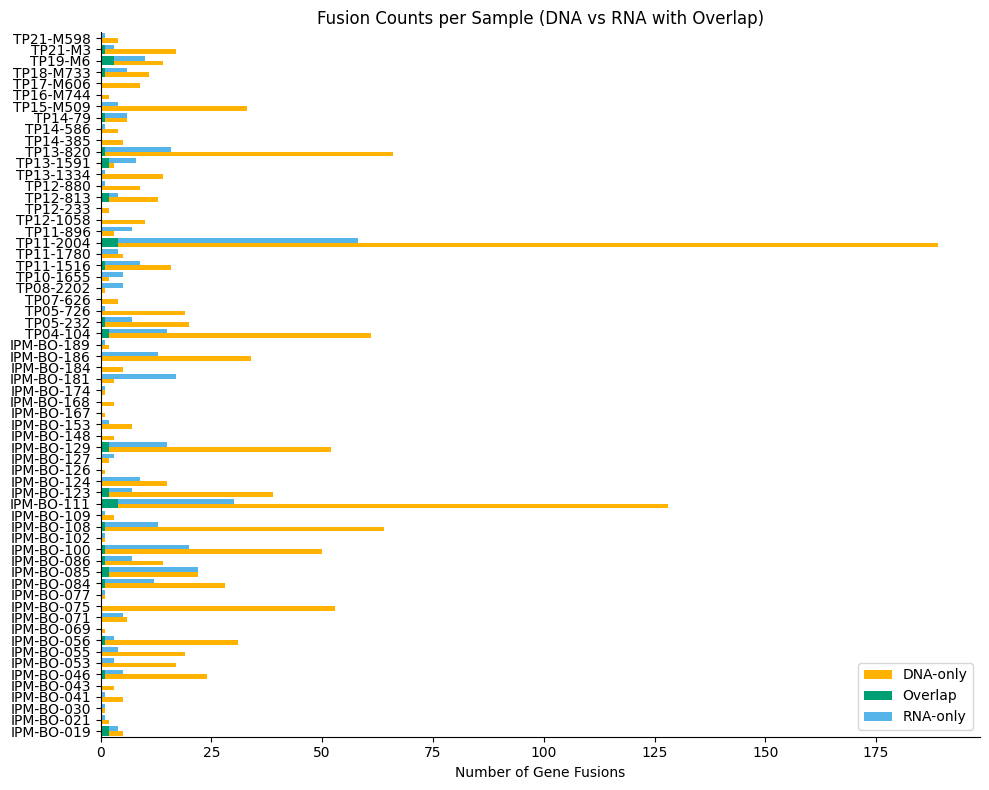

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import os

# === FILE PATHS ===
dna_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/DNA_SV_df.csv"
rna_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv"

# === LOAD FILES ===
dna_df = pd.read_csv(dna_path)
rna_df = pd.read_csv(rna_path)

# === FUNCTION: Extract per-sample fusion sets ===
def extract_fusions(df, fusion_col, sample_col):
    fusion_dict = defaultdict(set)
    for _, row in df[[fusion_col, sample_col]].dropna().iterrows():
        fusions = [f.strip() for f in str(row[fusion_col]).split(";") if f.strip() and f.strip() != "not_applicable"]
        fusion_dict[row[sample_col]].update(fusions)
    return fusion_dict

# === EXTRACT DNA & RNA FUSIONS ===
dna_fusions = extract_fusions(dna_df, "PutativeGeneFusion", "Sample_ID")
rna_fusions = extract_fusions(rna_df, "RNAFusion", "sample")

# === GET ALL UNIQUE SAMPLES ===
all_samples = sorted(set(dna_fusions.keys()).union(rna_fusions.keys()))

# === COMPUTE COUNTS ===
dna_only_counts, rna_only_counts, overlap_counts = [], [], []

for sample in all_samples:
    dna_set = dna_fusions.get(sample, set())
    rna_set = rna_fusions.get(sample, set())
    overlap = dna_set & rna_set
    dna_only = dna_set - overlap
    rna_only = rna_set - overlap
    dna_only_counts.append(len(dna_only))
    rna_only_counts.append(len(rna_only))
    overlap_counts.append(len(overlap))

# === PLOT ===
y_pos = np.arange(len(all_samples))
fig, ax = plt.subplots(figsize=(10, 8))

# Plot DNA-only and overlay overlap
ax.barh(y_pos - 0.2, dna_only_counts, height=0.4, color="#FFB300", label="DNA-only")
ax.barh(y_pos - 0.2, overlap_counts, height=0.4, color="#009E73", label="Overlap")

# Plot RNA-only and overlay overlap
ax.barh(y_pos + 0.2, rna_only_counts, height=0.4, color="#56B4E9", label="RNA-only")
ax.barh(y_pos + 0.2, overlap_counts, height=0.4, color="#009E73")

# Labels and layout
ax.set_yticks(y_pos)
ax.set_yticklabels(all_samples)
ax.set_xlabel("Number of Gene Fusions")
ax.set_title("Fusion Counts per Sample (DNA vs RNA with Overlap)")
ax.legend(loc="lower right")
plt.gca().invert_yaxis()
plt.tight_layout()
# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Adjust y-limits to remove top gap
ax.set_ylim(-0.5, len(all_samples) - 0.5)

# === SAVE PLOT IN SAME DIRECTORY ===
save_dir = os.path.dirname(rna_path)
plot_path = os.path.join(save_dir, "fusion_overlap_plot.png")
plt.savefig(plot_path, dpi=300)

print(f"✅ Plot saved at: {plot_path}")

plt.show()


✅ Plot saved to: /bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/mirrored_fusion_plot.png


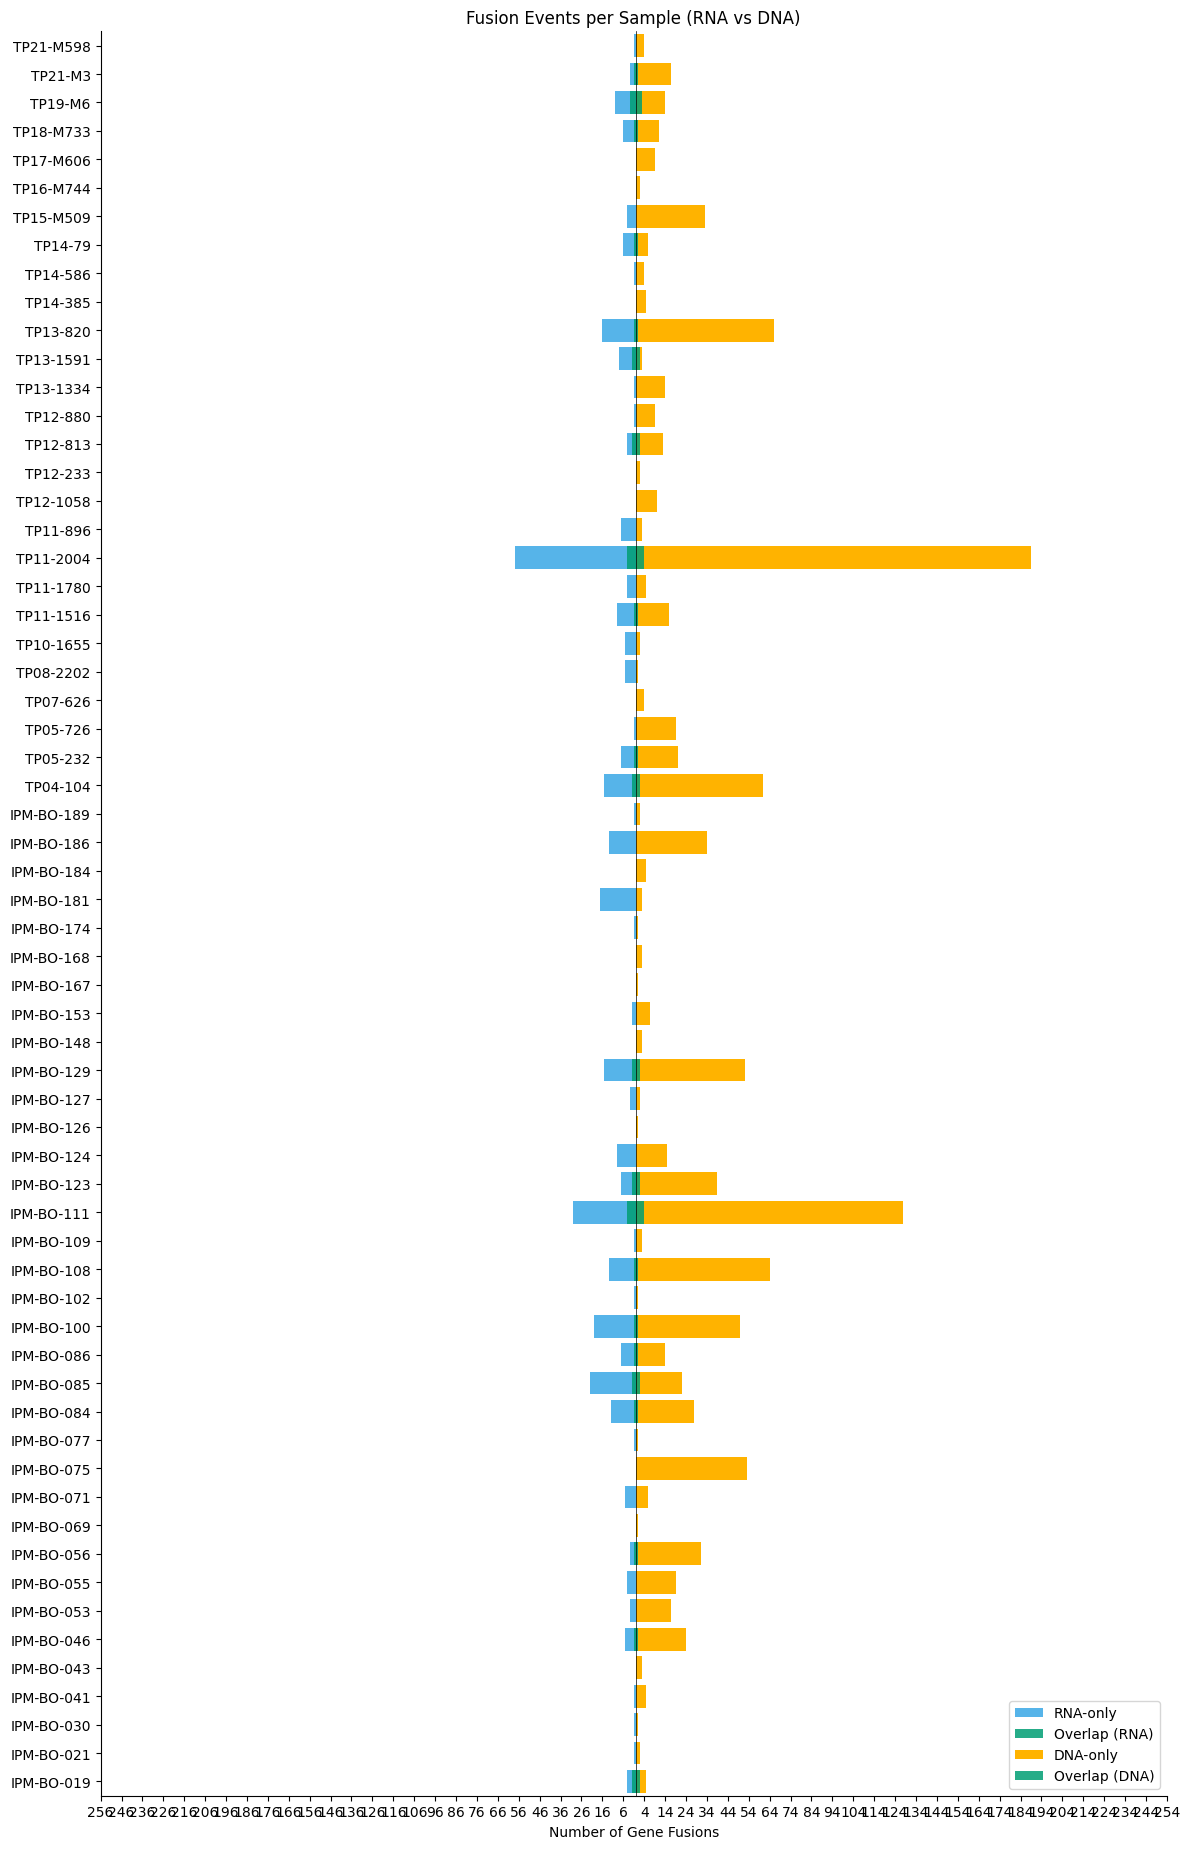

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from collections import defaultdict

# === FILE PATHS ===
dna_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/DNA_SV_df.csv"
rna_path = "/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv"

# === LOAD FILES ===
dna_df = pd.read_csv(dna_path)
rna_df = pd.read_csv(rna_path)

# === FUNCTION TO EXTRACT FUSIONS ===
def extract_fusions(df, fusion_col, sample_col):
    fusion_dict = defaultdict(set)
    for _, row in df[[fusion_col, sample_col]].dropna().iterrows():
        fusions = [f.strip() for f in str(row[fusion_col]).split(";") if f.strip() and f.strip() != "not_applicable"]
        fusion_dict[row[sample_col]].update(fusions)
    return fusion_dict

# === EXTRACT SAMPLE-WISE FUSIONS ===
dna_fusions = extract_fusions(dna_df, "PutativeGeneFusion", "Sample_ID")
rna_fusions = extract_fusions(rna_df, "RNAFusion", "sample")

# === UNION OF ALL SAMPLES ===
all_samples = sorted(set(dna_fusions.keys()).union(rna_fusions.keys()))

# === COLLECT COUNTS ===
data = []
for sample in all_samples:
    dna_set = dna_fusions.get(sample, set())
    rna_set = rna_fusions.get(sample, set())
    overlap = dna_set & rna_set
    dna_only = dna_set - overlap
    rna_only = rna_set - overlap
    data.append({
        "Sample": sample,
        "DNA-only": len(dna_only),
        "RNA-only": len(rna_only),
        "Overlap": len(overlap)
    })

df_plot = pd.DataFrame(data).sort_values("Sample")
samples = df_plot["Sample"]
y_pos = np.arange(len(samples))

# === PLOT SETUP ===
fig, ax = plt.subplots(figsize=(12, len(samples) * 0.3))

# Plot RNA-only (left, negative)
ax.barh(y_pos, -df_plot["RNA-only"], color="#56B4E9", label="RNA-only")
ax.barh(y_pos, -df_plot["Overlap"], color="#009E73", label="Overlap (RNA)", alpha=0.85)

# Plot DNA-only (right, positive)
ax.barh(y_pos, df_plot["DNA-only"], color="#FFB300", label="DNA-only")
ax.barh(y_pos, df_plot["Overlap"], color="#009E73", label="Overlap (DNA)", alpha=0.85)

# === AXIS CONFIG ===
ax.set_yticks(y_pos)
ax.set_yticklabels(samples)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel("Number of Gene Fusions")
ax.set_title("Fusion Events per Sample (RNA vs DNA)")
ax.invert_yaxis()

# Clean frame
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(-0.5, len(samples) - 0.5)

# X-ticks: mirrored absolute values
max_val = int(max(df_plot["DNA-only"] + df_plot["RNA-only"] + df_plot["Overlap"])) + 5
xticks = np.arange(-max_val, max_val + 1, step=10)
ax.set_xticks(xticks)
ax.set_xticklabels([abs(x) for x in xticks])

# === LEGEND ===
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc="lower right")

plt.tight_layout()

# === SAVE TO SAME DIRECTORY ===
save_dir = os.path.dirname(rna_path)
save_path = os.path.join(save_dir, "mirrored_fusion_plot.png")
plt.savefig(save_path, dpi=300)

print(f"✅ Plot saved to: {save_path}")
plt.show()


✅ Total fusion strings used for plotting: 1178
📊 Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/DNA_fusion_distribution_by_chr.png


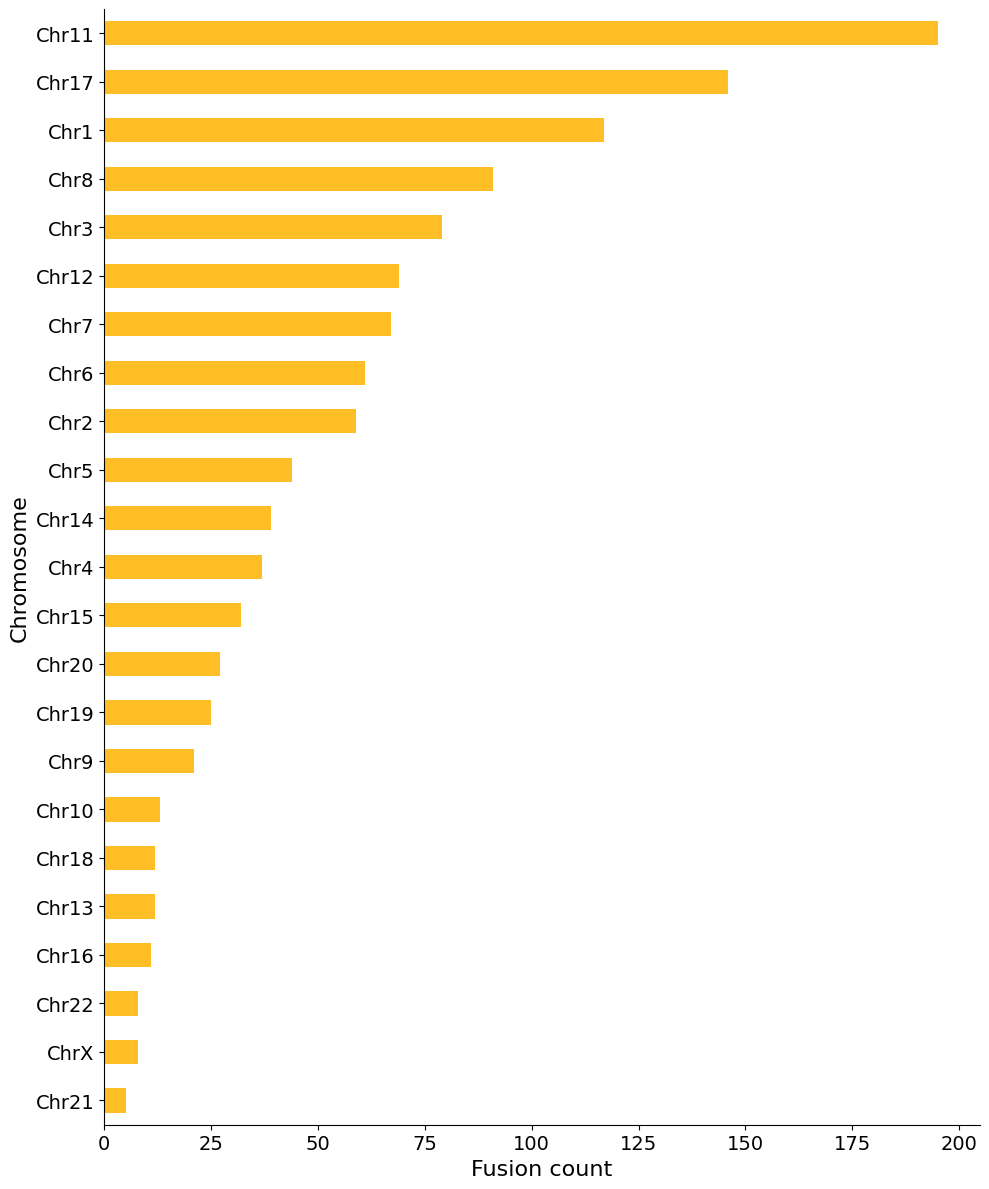

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion.csv"
df = pd.read_csv(file_path)

# Clean columns
df.columns = df.columns.str.strip()

# Keep valid fusion rows
df = df[df['PutativeGeneFusion'].notna()]
df = df[~df['PutativeGeneFusion'].isin(["", "not_applicable"])]

# Split fusion strings → one row per fusion
df_fusion = (
    df
    .assign(Fusion=df['PutativeGeneFusion'].str.split(";"))
    .explode('Fusion')
)

df_fusion['Fusion'] = df_fusion['Fusion'].str.strip()

print(f"✅ Total fusion strings used for plotting: {len(df_fusion)}")

fusion_counts = df_fusion['Chr'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 12))

fusion_counts.plot(
    kind='barh',
    color='#FFB300',
    alpha=0.85,
    ax=ax
)

ax.set_xlabel("Fusion count", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()

out = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/DNA_fusion_distribution_by_chr.png"
plt.savefig(out, dpi=300)
print(f"📊 Plot saved to: {out}")

plt.show()


✅ Total fusion strings used for plotting: 634
📊 Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_IPM.png


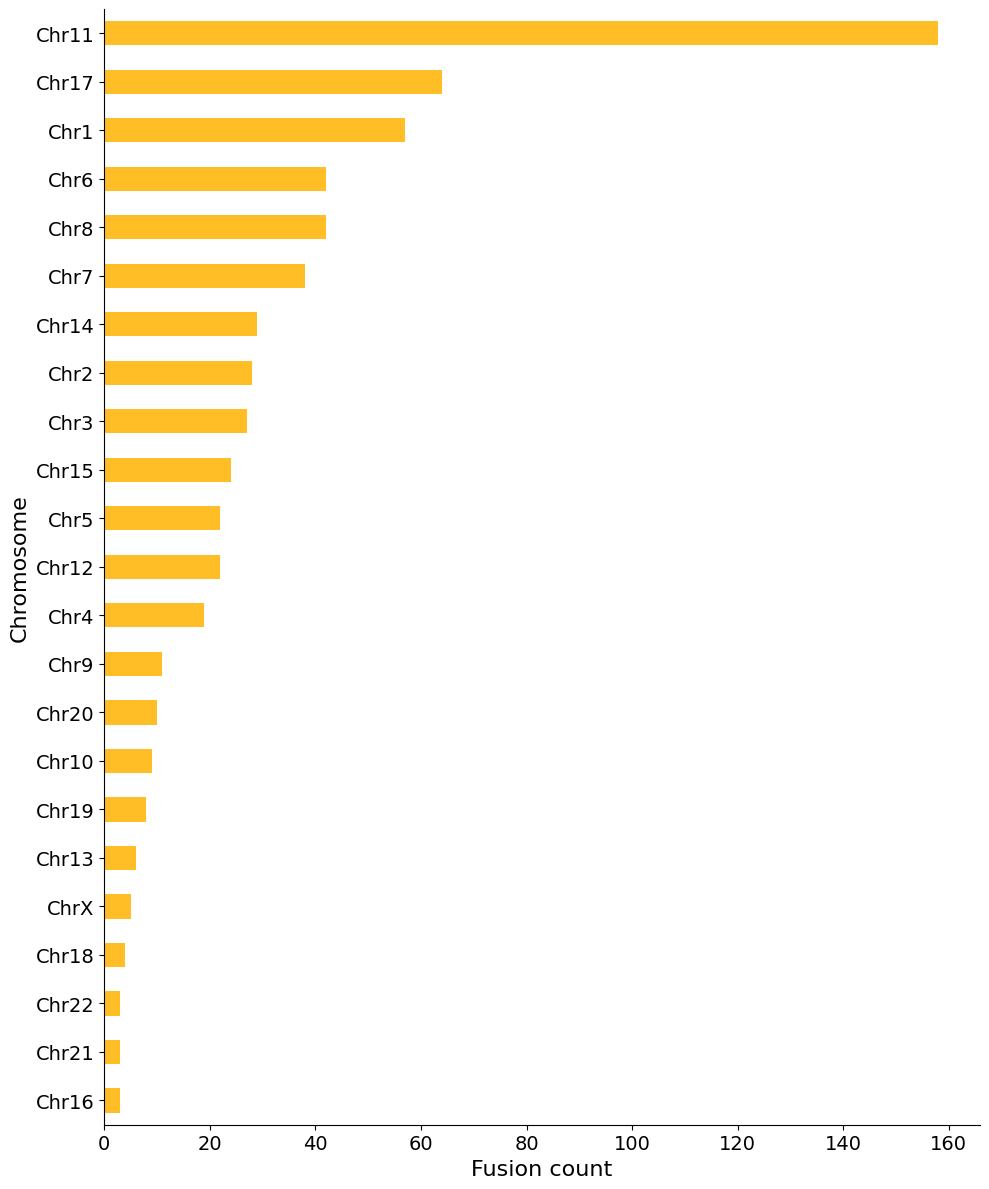

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion_IPM.csv"
df = pd.read_csv(file_path)

# Clean columns
df.columns = df.columns.str.strip()

# Keep valid fusion rows
df = df[df['PutativeGeneFusion'].notna()]
df = df[~df['PutativeGeneFusion'].isin(["", "not_applicable"])]

# Split fusion strings → one row per fusion
df_fusion = (
    df
    .assign(Fusion=df['PutativeGeneFusion'].str.split(";"))
    .explode('Fusion')
)

df_fusion['Fusion'] = df_fusion['Fusion'].str.strip()

print(f"✅ Total fusion strings used for plotting: {len(df_fusion)}")

fusion_counts = df_fusion['Chr'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 12))

fusion_counts.plot(
    kind='barh',
    color='#FFB300',
    alpha=0.85,
    ax=ax
)

ax.set_xlabel("Fusion count", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()

out = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_IPM.png"
plt.savefig(out, dpi=300)
print(f"📊 Plot saved to: {out}")

plt.show()


✅ Total fusion strings used for plotting: 544
📊 Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_Tumor.png


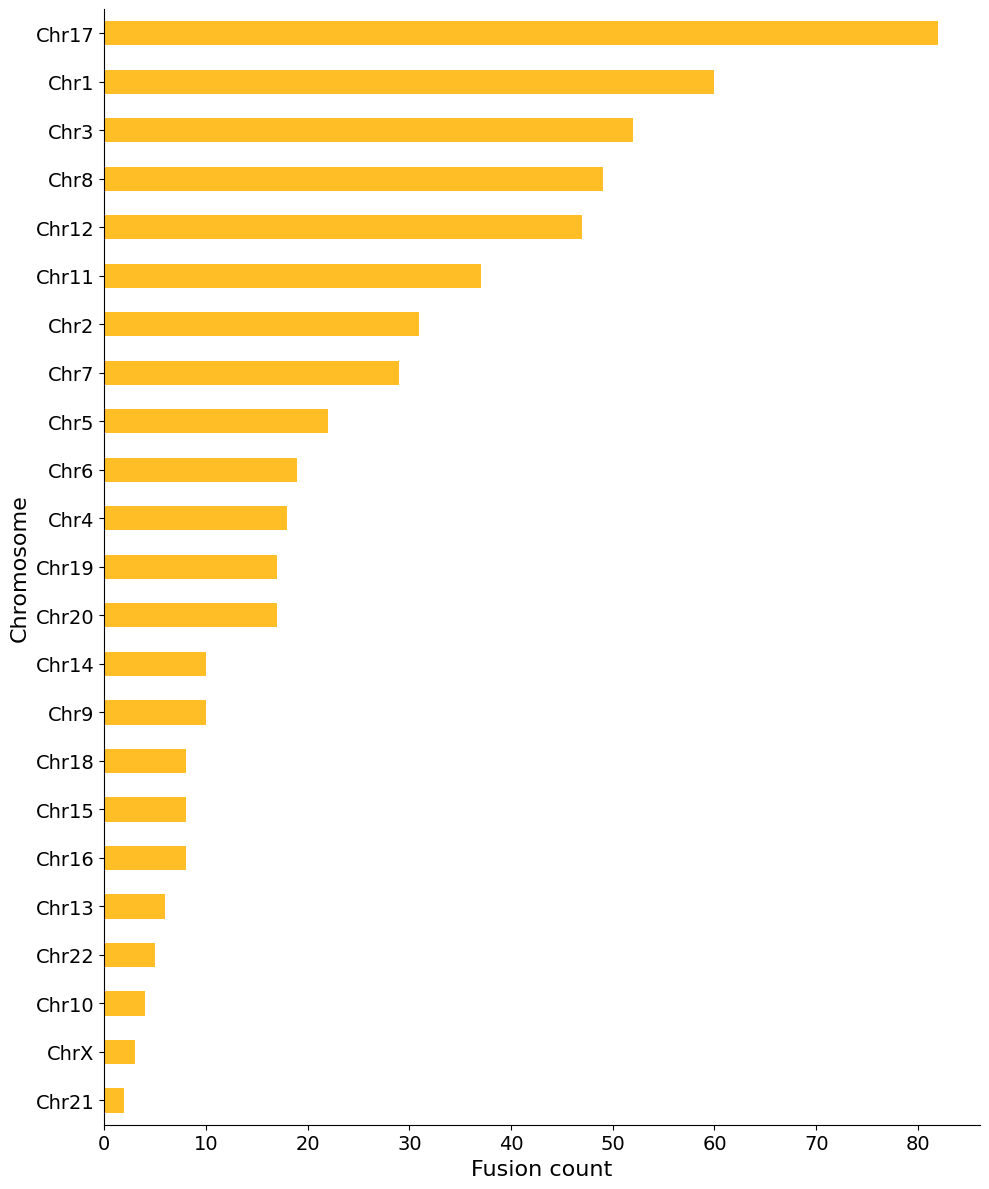

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion_Tumor.csv"
df = pd.read_csv(file_path)

# Clean columns
df.columns = df.columns.str.strip()

# Keep valid fusion rows
df = df[df['PutativeGeneFusion'].notna()]
df = df[~df['PutativeGeneFusion'].isin(["", "not_applicable"])]

# Split fusion strings → one row per fusion
df_fusion = (
    df
    .assign(Fusion=df['PutativeGeneFusion'].str.split(";"))
    .explode('Fusion')
)

df_fusion['Fusion'] = df_fusion['Fusion'].str.strip()

print(f"✅ Total fusion strings used for plotting: {len(df_fusion)}")

fusion_counts = df_fusion['Chr'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 12))

fusion_counts.plot(
    kind='barh',
    color='#FFB300',
    alpha=0.85,
    ax=ax
)

ax.set_xlabel("Fusion count", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()

out = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_Chromosome_Fusion_Counts_Tumor.png"
plt.savefig(out, dpi=300)
print(f"📊 Plot saved to: {out}")

plt.show()


✅ Total number of DNA fusions: 411
RNA fusion count plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts.png


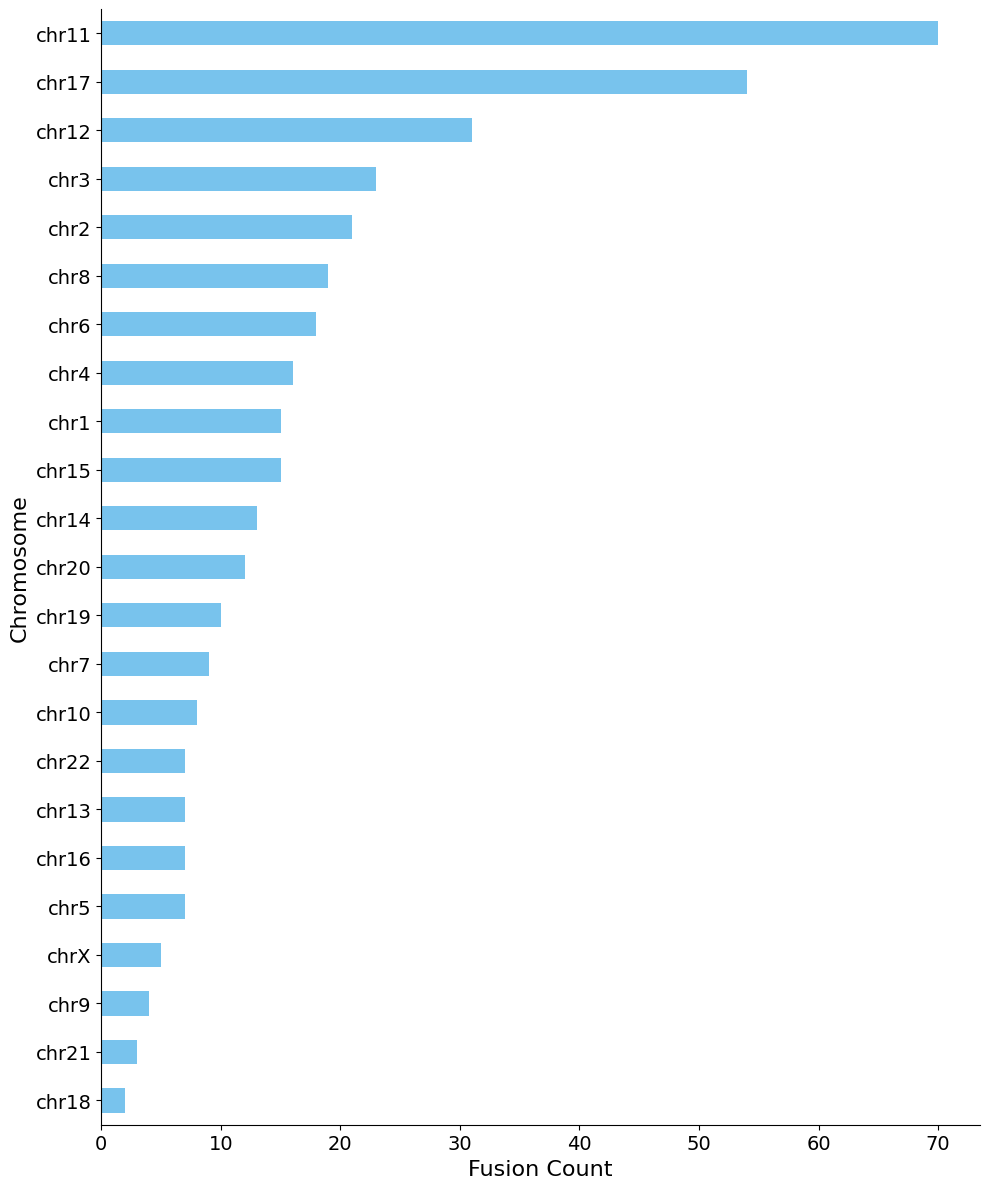

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# === Load Annotated RNA Fusion Data ===
file_path = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_with_chromosomes.csv'
df = pd.read_csv(file_path)
total_fusions = len(df)
print(f"✅ Total number of DNA fusions: {total_fusions}")

# === only want to count ChrA (the chromosome for GeneA) ===
chromosomes = df['ChrA']

# === Count and sort fusion events per chromosome ===
fusion_counts = chromosomes.value_counts().sort_values(ascending=True)

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 12))
fusion_counts.plot(
    kind='barh',
    color='#56B4E9',  # Light blue
    alpha=0.8,
    ax=ax
)

# === Customize Appearance ===
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlabel("Fusion Count", fontsize=16)
plt.ylabel("Chromosome", fontsize=16)
ax.tick_params(axis='both', labelsize=14)
# plt.title("RNA Fusion Events per Chromosome", fontsize=18)
plt.tight_layout()

# === Save Plot ===
output_file = '/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_Chromosome_Fusion_Counts.png'
os.makedirs(os.path.dirname(output_file), exist_ok=True)
plt.savefig(output_file, dpi=300)
print(f"RNA fusion count plot saved to: {output_file}")

plt.show()


In [7]:
import pandas as pd
import gzip

# === Step 1: Load FusionCatcher CSV ===
fusion_df = pd.read_csv('/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_df.csv')

# === Step 2: Safely split fusion gene names using single dash (-)
# Some gene names may have internal dashes, so split only on the first one
fusion_df[['GeneA', 'GeneB']] = fusion_df['RNAFusion'].str.split('-', n=1, expand=True)

# === Step 3: Parse GTF file and build gene-to-chromosome map ===
def parse_gtf(gtf_path):
    gene_chr_map = {}
    open_func = gzip.open if gtf_path.endswith(".gz") else open
    with open_func(gtf_path, 'rt') as gtf:
        for line in gtf:
            if line.startswith('#'):
                continue
            cols = line.strip().split('\t')
            if len(cols) < 9 or cols[2] != 'gene':
                continue
            chrom = cols[0]
            attributes = cols[8]
            attrs = {}
            for attr in attributes.strip().split(';'):
                if attr.strip():
                    key_value = attr.strip().split(' ', 1)
                    if len(key_value) == 2:
                        key, value = key_value
                        attrs[key] = value.strip('"')
            gene_name = attrs.get('gene_name')
            if gene_name and gene_name not in gene_chr_map:
                gene_chr_map[gene_name] = chrom
    return gene_chr_map

# === Step 4: Load your actual GTF file ===
gtf_file = '/bgfs/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf'
gene_chr = parse_gtf(gtf_file)

# === Step 5: Annotate with chromosome info ===
fusion_df['ChrA'] = fusion_df['GeneA'].map(gene_chr)
fusion_df['ChrB'] = fusion_df['GeneB'].map(gene_chr)

# === Step 6: Save the result ===
fusion_df.to_csv('/bgfs/alee/LO_LAB/Personal/Rahul/BioNano/SVs/RNA_SV_with_chromosomes.csv', index=False)

# === Step 7: Preview result ===
print(fusion_df[['RNAFusion', 'GeneA', 'ChrA', 'GeneB', 'ChrB']].head())


       RNAFusion    GeneA   ChrA    GeneB   ChrB
0     EDC3-PREX1     EDC3  chr15    PREX1  chr20
1     PREX1-EDC3    PREX1  chr20     EDC3  chr15
2   CTTN-BDNF-AS     CTTN  chr11  BDNF-AS  chr11
3  PPFIA1-KIF18A   PPFIA1  chr11   KIF18A  chr11
4  PPFIBP2-KMT5B  PPFIBP2  chr11    KMT5B  chr11


In [8]:
#!/usr/bin/env python3

import os
import re
import sys
import pandas as pd

# =========================
# Inputs
# =========================
TCGA_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Reference/TCGA.BRCA.onco.genes.OncoVar.tsv"
ICGC_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Reference/ICGC.BRCA.onco.genes.OncoVar.tsv"
SV_CSV   = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion_IPM.csv"

GENE_COL   = "Gene_symbol"
FUSION_COL = "PutativeGeneFusion"

# =========================
# Output
# =========================
OUT_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM"
OUT_PREFIX = "BRCA_fusion_mapping"
os.makedirs(OUT_DIR, exist_ok=True)

INVALID_FUSION_STRINGS = {"", "-", "NA", "NaN", "nan", "None", "not_applicable"}

# =========================
# Helpers
# =========================
def read_gene_list(tsv_path: str) -> pd.Series:
    df = pd.read_csv(tsv_path, sep="\t", dtype=str)
    if GENE_COL not in df.columns:
        raise ValueError(
            f"[ERROR] Column '{GENE_COL}' not found in {tsv_path}. "
            f"Available columns: {list(df.columns)}"
        )
    genes = (
        df[GENE_COL]
        .dropna()
        .astype(str)
        .str.strip()
    )
    genes = genes[~genes.isin(INVALID_FUSION_STRINGS)]
    return genes

def parse_fusion_pair(fusion: str):
    """
    Parse one fusion token into (GeneA, GeneB).
    Accepts: GENE1-GENE2 or GENE1:GENE2
    Returns (None, None) if can't parse cleanly.
    """
    if fusion is None:
        return (None, None)

    token = str(fusion).strip()
    if token in INVALID_FUSION_STRINGS:
        return (None, None)

    parts = re.split(r"[-:]", token, maxsplit=1)
    if len(parts) != 2:
        return (None, None)

    gene_a = parts[0].strip()
    gene_b = parts[1].strip()
    if not gene_a or not gene_b:
        return (None, None)
    return (gene_a, gene_b)

def to_numeric(series: pd.Series) -> pd.Series:
    """Convert to numeric safely; returns float with NaNs where conversion fails."""
    return pd.to_numeric(series, errors="coerce")

# =========================
# Main
# =========================
def main():
    # ---------
    # Load SV
    # ---------
    df = pd.read_csv(SV_CSV, dtype=str)
    df.columns = df.columns.str.strip()

    if FUSION_COL not in df.columns:
        raise ValueError(
            f"[ERROR] Column '{FUSION_COL}' not found in {SV_CSV}. "
            f"Available columns: {list(df.columns)}"
        )

    # -----------------------------------------
    # Sanity: keep valid rows, split multi-fusions, explode
    # -----------------------------------------
    df_valid = df[df[FUSION_COL].notna()].copy()
    df_valid[FUSION_COL] = df_valid[FUSION_COL].astype(str).str.strip()
    df_valid = df_valid[~df_valid[FUSION_COL].isin(INVALID_FUSION_STRINGS)]

    df_fusion = (
        df_valid
        .assign(Fusion=df_valid[FUSION_COL].str.split(";"))
        .explode("Fusion")
        .copy()
    )
    df_fusion["Fusion"] = df_fusion["Fusion"].astype(str).str.strip()
    df_fusion = df_fusion[~df_fusion["Fusion"].isin(INVALID_FUSION_STRINGS)]

    print(f"✅ Total fusion strings used for mapping: {len(df_fusion)}")

    # -----------------------------------------
    # Parse GeneA/GeneB from each fusion token
    # -----------------------------------------
    parsed = df_fusion["Fusion"].apply(parse_fusion_pair)
    df_fusion["GeneA"] = parsed.apply(lambda x: x[0])
    df_fusion["GeneB"] = parsed.apply(lambda x: x[1])

    df_fusion_parsed = df_fusion.dropna(subset=["GeneA", "GeneB"]).copy()
    print(f"✅ Parseable gene pairs (GeneA/GeneB): {len(df_fusion_parsed)}\n")

    # -----------------------------------------
    # Add breakpoint columns for circos
    # -----------------------------------------
    # Expected columns in your SV file:
    # RefcontigID1, RefcontigID2, RefStartPos, RefEndPos
    # These represent the reference interval for the SV call.
    required_bp_cols = ["RefcontigID1", "RefcontigID2", "RefStartPos", "RefEndPos"]
    missing = [c for c in required_bp_cols if c not in df_fusion_parsed.columns]
    if missing:
        print(f"[WARN] Missing breakpoint columns in SV file: {missing}")
    else:
        # Convert positions to numeric (float)
        df_fusion_parsed["RefStartPos_num"] = to_numeric(df_fusion_parsed["RefStartPos"])
        df_fusion_parsed["RefEndPos_num"]   = to_numeric(df_fusion_parsed["RefEndPos"])

        # Define A-side and B-side breakpoints.
        # In this OGM table, RefStartPos/RefEndPos correspond to the reference interval.
        # We will store the same interval for both sides when only one interval is available,
        # but still keep ChrA/ChrB distinct using RefcontigID1/2 (important for inter events).
        df_fusion_parsed["ChrA"] = df_fusion_parsed["RefcontigID1"]
        df_fusion_parsed["ChrB"] = df_fusion_parsed["RefcontigID2"]

        # Use interval start/end as the span
        df_fusion_parsed["StartA"] = df_fusion_parsed["RefStartPos_num"]
        df_fusion_parsed["EndA"]   = df_fusion_parsed["RefEndPos_num"]
        df_fusion_parsed["StartB"] = df_fusion_parsed["RefStartPos_num"]
        df_fusion_parsed["EndB"]   = df_fusion_parsed["RefEndPos_num"]

        # A single coordinate per side (midpoint) for circos links
        df_fusion_parsed["PosA"] = ((df_fusion_parsed["StartA"] + df_fusion_parsed["EndA"]) / 2).round().astype("Int64")
        df_fusion_parsed["PosB"] = ((df_fusion_parsed["StartB"] + df_fusion_parsed["EndB"]) / 2).round().astype("Int64")

        # Clean up helper numeric cols if you don’t want them
        df_fusion_parsed.drop(columns=["RefStartPos_num", "RefEndPos_num"], inplace=True, errors="ignore")

    # ---------
    # Load BRCA gene lists
    # ---------
    tcga_genes = read_gene_list(TCGA_TSV)
    icgc_genes = read_gene_list(ICGC_TSV)
    brca_genes = set(pd.concat([tcga_genes, icgc_genes], ignore_index=True).unique())

    # -----------------------------------------
    # Map BRCA matches
    # -----------------------------------------
    df_fusion_parsed["GeneA_in_BRCA"] = df_fusion_parsed["GeneA"].isin(brca_genes)
    df_fusion_parsed["GeneB_in_BRCA"] = df_fusion_parsed["GeneB"].isin(brca_genes)

    df_fusion_parsed["BRCA_match_type"] = "No_BRCA_gene"
    df_fusion_parsed.loc[
        df_fusion_parsed["GeneA_in_BRCA"] & df_fusion_parsed["GeneB_in_BRCA"],
        "BRCA_match_type"
    ] = "Both_genes_BRCA"
    df_fusion_parsed.loc[
        df_fusion_parsed["GeneA_in_BRCA"] ^ df_fusion_parsed["GeneB_in_BRCA"],
        "BRCA_match_type"
    ] = "One_gene_BRCA"

    both_df = df_fusion_parsed[df_fusion_parsed["BRCA_match_type"] == "Both_genes_BRCA"].copy()
    one_df  = df_fusion_parsed[df_fusion_parsed["BRCA_match_type"] == "One_gene_BRCA"].copy()

    # -----------------------------------------
    # Keep columns (remove redundant 'Chr', keep ChrA/ChrB/PosA/PosB)
    # -----------------------------------------
    keep_cols = [c for c in [
        "Sample", "sample",
        FUSION_COL, "Fusion",
        "GeneA", "GeneB",
        "GeneA_in_BRCA", "GeneB_in_BRCA",
        "BRCA_match_type",

        # circos-ready breakpoints
        "ChrA", "PosA", "ChrB", "PosB",
        "StartA", "EndA", "StartB", "EndB",

        # SV metadata
        "Type", "RefcontigID1", "RefcontigID2", "ISCN"
    ] if c in df_fusion_parsed.columns]

    # ---------
    # Write outputs
    # ---------
    out_all  = os.path.join(OUT_DIR, f"{OUT_PREFIX}.all_annotated.tsv")
    out_both = os.path.join(OUT_DIR, f"{OUT_PREFIX}.both_genes.tsv")
    out_one  = os.path.join(OUT_DIR, f"{OUT_PREFIX}.one_gene.tsv")

    df_fusion_parsed[keep_cols].to_csv(out_all, sep="\t", index=False)
    both_df[keep_cols].to_csv(out_both, sep="\t", index=False)
    one_df[keep_cols].to_csv(out_one, sep="\t", index=False)

    print("=== BRCA fusion mapping DONE ===")
    print(f"Unique BRCA genes (TCGA+ICGC): {len(brca_genes):,}")
    print(f"Total parsed fusions          : {len(df_fusion_parsed):,}")
    print(f"Both genes BRCA               : {len(both_df):,}")
    print(f"One gene BRCA                 : {len(one_df):,}")
    print("Outputs:")
    print(f"  {out_all}")
    print(f"  {out_both}")
    print(f"  {out_one}")

if __name__ == "__main__":
    try:
        main()
    except Exception as e:
        print(str(e), file=sys.stderr)
        sys.exit(1)


✅ Total fusion strings used for mapping: 634
✅ Parseable gene pairs (GeneA/GeneB): 634

=== BRCA fusion mapping DONE ===
Unique BRCA genes (TCGA+ICGC): 79
Total parsed fusions          : 634
Both genes BRCA               : 0
One gene BRCA                 : 7
Outputs:
  /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/BRCA_fusion_mapping.all_annotated.tsv
  /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/BRCA_fusion_mapping.both_genes.tsv
  /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/BRCA_fusion_mapping.one_gene.tsv


In [9]:
#!/usr/bin/env python3

import os
import re
import sys
import pandas as pd

# =========================
# Inputs
# =========================
TCGA_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Reference/TCGA.BRCA.onco.genes.OncoVar.tsv"
ICGC_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Reference/ICGC.BRCA.onco.genes.OncoVar.tsv"
SV_CSV   = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/SVs/SV_df_DNA_fusion_Tumor.csv"

GENE_COL   = "Gene_symbol"
FUSION_COL = "PutativeGeneFusion"

# =========================
# Output
# =========================
OUT_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor"
OUT_PREFIX = "BRCA_fusion_mapping"
os.makedirs(OUT_DIR, exist_ok=True)

INVALID_FUSION_STRINGS = {"", "-", "NA", "NaN", "nan", "None", "not_applicable"}

# =========================
# Helpers
# =========================
def read_gene_list(tsv_path: str) -> pd.Series:
    df = pd.read_csv(tsv_path, sep="\t", dtype=str)
    if GENE_COL not in df.columns:
        raise ValueError(
            f"[ERROR] Column '{GENE_COL}' not found in {tsv_path}. "
            f"Available columns: {list(df.columns)}"
        )
    genes = (
        df[GENE_COL]
        .dropna()
        .astype(str)
        .str.strip()
    )
    genes = genes[~genes.isin(INVALID_FUSION_STRINGS)]
    return genes

def parse_fusion_pair(fusion: str):
    """
    Parse one fusion token into (GeneA, GeneB).
    Accepts: GENE1-GENE2 or GENE1:GENE2
    Returns (None, None) if can't parse cleanly.
    """
    if fusion is None:
        return (None, None)

    token = str(fusion).strip()
    if token in INVALID_FUSION_STRINGS:
        return (None, None)

    parts = re.split(r"[-:]", token, maxsplit=1)
    if len(parts) != 2:
        return (None, None)

    gene_a = parts[0].strip()
    gene_b = parts[1].strip()
    if not gene_a or not gene_b:
        return (None, None)
    return (gene_a, gene_b)

def to_numeric(series: pd.Series) -> pd.Series:
    """Convert to numeric safely; returns float with NaNs where conversion fails."""
    return pd.to_numeric(series, errors="coerce")

# =========================
# Main
# =========================
def main():
    # ---------
    # Load SV
    # ---------
    df = pd.read_csv(SV_CSV, dtype=str)
    df.columns = df.columns.str.strip()

    if FUSION_COL not in df.columns:
        raise ValueError(
            f"[ERROR] Column '{FUSION_COL}' not found in {SV_CSV}. "
            f"Available columns: {list(df.columns)}"
        )

    # -----------------------------------------
    # Sanity: keep valid rows, split multi-fusions, explode
    # -----------------------------------------
    df_valid = df[df[FUSION_COL].notna()].copy()
    df_valid[FUSION_COL] = df_valid[FUSION_COL].astype(str).str.strip()
    df_valid = df_valid[~df_valid[FUSION_COL].isin(INVALID_FUSION_STRINGS)]

    df_fusion = (
        df_valid
        .assign(Fusion=df_valid[FUSION_COL].str.split(";"))
        .explode("Fusion")
        .copy()
    )
    df_fusion["Fusion"] = df_fusion["Fusion"].astype(str).str.strip()
    df_fusion = df_fusion[~df_fusion["Fusion"].isin(INVALID_FUSION_STRINGS)]

    print(f"✅ Total fusion strings used for mapping: {len(df_fusion)}")

    # -----------------------------------------
    # Parse GeneA/GeneB from each fusion token
    # -----------------------------------------
    parsed = df_fusion["Fusion"].apply(parse_fusion_pair)
    df_fusion["GeneA"] = parsed.apply(lambda x: x[0])
    df_fusion["GeneB"] = parsed.apply(lambda x: x[1])

    df_fusion_parsed = df_fusion.dropna(subset=["GeneA", "GeneB"]).copy()
    print(f"✅ Parseable gene pairs (GeneA/GeneB): {len(df_fusion_parsed)}\n")

    # -----------------------------------------
    # Add breakpoint columns for circos
    # -----------------------------------------
    # Expected columns in your SV file:
    # RefcontigID1, RefcontigID2, RefStartPos, RefEndPos
    # These represent the reference interval for the SV call.
    required_bp_cols = ["RefcontigID1", "RefcontigID2", "RefStartPos", "RefEndPos"]
    missing = [c for c in required_bp_cols if c not in df_fusion_parsed.columns]
    if missing:
        print(f"[WARN] Missing breakpoint columns in SV file: {missing}")
    else:
        # Convert positions to numeric (float)
        df_fusion_parsed["RefStartPos_num"] = to_numeric(df_fusion_parsed["RefStartPos"])
        df_fusion_parsed["RefEndPos_num"]   = to_numeric(df_fusion_parsed["RefEndPos"])

        # Define A-side and B-side breakpoints.
        # In this OGM table, RefStartPos/RefEndPos correspond to the reference interval.
        # We will store the same interval for both sides when only one interval is available,
        # but still keep ChrA/ChrB distinct using RefcontigID1/2 (important for inter events).
        df_fusion_parsed["ChrA"] = df_fusion_parsed["RefcontigID1"]
        df_fusion_parsed["ChrB"] = df_fusion_parsed["RefcontigID2"]

        # Use interval start/end as the span
        df_fusion_parsed["StartA"] = df_fusion_parsed["RefStartPos_num"]
        df_fusion_parsed["EndA"]   = df_fusion_parsed["RefEndPos_num"]
        df_fusion_parsed["StartB"] = df_fusion_parsed["RefStartPos_num"]
        df_fusion_parsed["EndB"]   = df_fusion_parsed["RefEndPos_num"]

        # A single coordinate per side (midpoint) for circos links
        df_fusion_parsed["PosA"] = ((df_fusion_parsed["StartA"] + df_fusion_parsed["EndA"]) / 2).round().astype("Int64")
        df_fusion_parsed["PosB"] = ((df_fusion_parsed["StartB"] + df_fusion_parsed["EndB"]) / 2).round().astype("Int64")

        # Clean up helper numeric cols if you don’t want them
        df_fusion_parsed.drop(columns=["RefStartPos_num", "RefEndPos_num"], inplace=True, errors="ignore")

    # ---------
    # Load BRCA gene lists
    # ---------
    tcga_genes = read_gene_list(TCGA_TSV)
    icgc_genes = read_gene_list(ICGC_TSV)
    brca_genes = set(pd.concat([tcga_genes, icgc_genes], ignore_index=True).unique())

    # -----------------------------------------
    # Map BRCA matches
    # -----------------------------------------
    df_fusion_parsed["GeneA_in_BRCA"] = df_fusion_parsed["GeneA"].isin(brca_genes)
    df_fusion_parsed["GeneB_in_BRCA"] = df_fusion_parsed["GeneB"].isin(brca_genes)

    df_fusion_parsed["BRCA_match_type"] = "No_BRCA_gene"
    df_fusion_parsed.loc[
        df_fusion_parsed["GeneA_in_BRCA"] & df_fusion_parsed["GeneB_in_BRCA"],
        "BRCA_match_type"
    ] = "Both_genes_BRCA"
    df_fusion_parsed.loc[
        df_fusion_parsed["GeneA_in_BRCA"] ^ df_fusion_parsed["GeneB_in_BRCA"],
        "BRCA_match_type"
    ] = "One_gene_BRCA"

    both_df = df_fusion_parsed[df_fusion_parsed["BRCA_match_type"] == "Both_genes_BRCA"].copy()
    one_df  = df_fusion_parsed[df_fusion_parsed["BRCA_match_type"] == "One_gene_BRCA"].copy()

    # -----------------------------------------
    # Keep columns (remove redundant 'Chr', keep ChrA/ChrB/PosA/PosB)
    # -----------------------------------------
    keep_cols = [c for c in [
        "Sample", "sample",
        FUSION_COL, "Fusion",
        "GeneA", "GeneB",
        "GeneA_in_BRCA", "GeneB_in_BRCA",
        "BRCA_match_type",

        # circos-ready breakpoints
        "ChrA", "PosA", "ChrB", "PosB",
        "StartA", "EndA", "StartB", "EndB",

        # SV metadata
        "Type", "RefcontigID1", "RefcontigID2", "ISCN"
    ] if c in df_fusion_parsed.columns]

    # ---------
    # Write outputs
    # ---------
    out_all  = os.path.join(OUT_DIR, f"{OUT_PREFIX}.all_annotated.tsv")
    out_both = os.path.join(OUT_DIR, f"{OUT_PREFIX}.both_genes.tsv")
    out_one  = os.path.join(OUT_DIR, f"{OUT_PREFIX}.one_gene.tsv")

    df_fusion_parsed[keep_cols].to_csv(out_all, sep="\t", index=False)
    both_df[keep_cols].to_csv(out_both, sep="\t", index=False)
    one_df[keep_cols].to_csv(out_one, sep="\t", index=False)

    print("=== BRCA fusion mapping DONE ===")
    print(f"Unique BRCA genes (TCGA+ICGC): {len(brca_genes):,}")
    print(f"Total parsed fusions          : {len(df_fusion_parsed):,}")
    print(f"Both genes BRCA               : {len(both_df):,}")
    print(f"One gene BRCA                 : {len(one_df):,}")
    print("Outputs:")
    print(f"  {out_all}")
    print(f"  {out_both}")
    print(f"  {out_one}")

if __name__ == "__main__":
    try:
        main()
    except Exception as e:
        print(str(e), file=sys.stderr)
        sys.exit(1)


✅ Total fusion strings used for mapping: 544
✅ Parseable gene pairs (GeneA/GeneB): 544

=== BRCA fusion mapping DONE ===
Unique BRCA genes (TCGA+ICGC): 79
Total parsed fusions          : 544
Both genes BRCA               : 0
One gene BRCA                 : 15
Outputs:
  /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/BRCA_fusion_mapping.all_annotated.tsv
  /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/BRCA_fusion_mapping.both_genes.tsv
  /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/BRCA_fusion_mapping.one_gene.tsv


In [5]:
import os
import re
import pandas as pd

# ----------------------------
# Inputs
# ----------------------------
EXP_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/functional_fusions_expression_only_IPM.csv"
BRCA_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/BRCA_fusion_mapping.one_gene.tsv"

OUT_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/functional_fusions_expression_only_IPM.BRCA_only.csv"

# ----------------------------
# Sanity: paths
# ----------------------------
for p in [EXP_CSV, BRCA_TSV]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing file: {p}")

# ----------------------------
# Read files
# ----------------------------
exp = pd.read_csv(EXP_CSV)
brca = pd.read_csv(BRCA_TSV, sep="\t")

print("Loaded:")
print("  exp :", exp.shape)
print("  brca:", brca.shape)

# ----------------------------
# Sanity: required columns
# ----------------------------
req_exp  = {"fusions", "fusions_inv", "samples"}
req_brca = {"PutativeGeneFusion"}  # Sample not required for filtering; only fusion list is needed

missing_exp  = req_exp  - set(exp.columns)
missing_brca = req_brca - set(brca.columns)

if missing_exp:
    raise ValueError(f"EXP missing columns: {sorted(missing_exp)}")
if missing_brca:
    raise ValueError(f"BRCA missing columns: {sorted(missing_brca)}")

# ----------------------------
# Normalize fusion strings for robust matching
# ----------------------------
def norm_fusion(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    x = " ".join(x.split())  # collapse internal whitespace
    return x

exp["fusions_norm"]     = exp["fusions"].map(norm_fusion)
exp["fusions_inv_norm"] = exp["fusions_inv"].map(norm_fusion)

# sanity: any null fusion ids?
if exp["fusions_norm"].isna().any():
    n_na = exp["fusions_norm"].isna().sum()
    raise ValueError(f"EXP has {n_na} rows with NA in 'fusions' (cannot match). Fix upstream or drop them.")

# ----------------------------
# Build BRCA fusion set (SPLIT multi-fusion cells like 'A-B;A-C')
# ----------------------------
def split_fusions(cell):
    if pd.isna(cell):
        return []
    s = str(cell).strip()
    # split on ; or , just in case
    parts = re.split(r"[;,]", s)
    parts = [norm_fusion(p) for p in parts]
    return [p for p in parts if p]

brca_set = set()
for cell in brca["PutativeGeneFusion"].dropna():
    for f in split_fusions(cell):
        brca_set.add(f)

print(f"Unique BRCA fusions (after splitting): {len(brca_set)}")
print(f"Unique EXP fusions: {exp['fusions_norm'].nunique()}")

# ----------------------------
# Filter EXP rows whose fusion OR inverted fusion is in BRCA set
# ----------------------------
mask = exp["fusions_norm"].isin(brca_set) | exp["fusions_inv_norm"].isin(brca_set)
exp_brca = exp.loc[mask].copy()

print("Matched rows:", exp_brca.shape)

# ----------------------------
# Sanity: show match rate + examples of misses
# ----------------------------
match_rate = exp_brca.shape[0] / exp.shape[0] if exp.shape[0] else 0
print(f"Match rate: {match_rate:.3f}")

# Which BRCA fusions are NOT found in EXP (either direction)?
exp_all_fusions = set(exp["fusions_norm"].dropna().unique()) | set(exp["fusions_inv_norm"].dropna().unique())
brca_not_found = sorted(list(brca_set - exp_all_fusions))
print(f"BRCA fusions not found in EXP (count={len(brca_not_found)}). Showing up to 15:")
print(brca_not_found[:15])

# Optional: duplicates check (same fusion+sample)
dup_cols = ["samples", "fusions_norm"]
dups = exp_brca.duplicated(subset=dup_cols).sum()
print(f"Duplicate rows in output by {dup_cols}: {dups}")

# ----------------------------
# Clean up helper columns + write output
# ----------------------------
exp_brca.drop(columns=["fusions_norm", "fusions_inv_norm"], inplace=True)

out_dir = os.path.dirname(OUT_CSV)
os.makedirs(out_dir, exist_ok=True)

exp_brca.to_csv(OUT_CSV, index=False)
print("Wrote:", OUT_CSV)

display(exp_brca.head(10))


Loaded:
  exp : (333, 19)
  brca: (7, 21)
Unique BRCA fusions (after splitting): 7
Unique EXP fusions: 333
Matched rows: (6, 21)
Match rate: 0.018
BRCA fusions not found in EXP (count=1). Showing up to 15:
['FGFR2-AC025265.1']
Duplicate rows in output by ['samples', 'fusions_norm']: 0
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/IPM/functional_fusions_expression_only_IPM.BRCA_only.csv


,fusions,samples,type,geneA,chrA,StartA,EndA,geneB,chrB,StartB,EndB,fusions_inv,geneA_exp,geneB_exp,geneA_status,geneB_status,geneA_OncoTS,geneB_OncoTS,exp
64,PVT1-PSIP1,IPM-BO-085,Transloc-Inter,PVT1,chr8,127882084,127882084,PSIP1,chr9,15481242,15481242,PSIP1-PVT1,0.030807,2.464708,normal,dn,NaN,NaN,down-regulation
66,METTL16-BRCA1,IPM-BO-085,Transloc-Intra,METTL16,chr17,2493012,2493012,BRCA1,chr17,43124641,43124641,BRCA1-METTL16,0.230532,0.226282,up,up,NaN,TSG,up-regulation
95,CCDC170-ESR1,IPM-BO-100,Dup,CCDC170,chr6,151610559,151610559,ESR1,chr6,151741689,151741689,ESR1-CCDC170,0.329338,1.360451,normal,up,NaN,Oncogene,up-regulation
117,RPL5-TMED5,IPM-BO-108,Dup,RPL5,chr1,92834827,92834827,TMED5,chr1,93172071,93172071,TMED5-RPL5,3.012037,1.431818,normal,up,NaN,NaN,up-regulation
211,POP7-RB1,IPM-BO-124,Transloc-Inter,POP7,chr7,100706619,100706619,RB1,chr13,48360841,48360841,RB1-POP7,1.829226,0.180698,up,dn,NaN,TSG,up-regulation
318,FGFR2-STAB2,IPM-BO-129,Transloc-Inter,FGFR2,chr10,121482630,121482630,STAB2,chr12,103762579,103762579,STAB2-FGFR2,0.000000,0.048704,normal,dn,Oncogene,NaN,down-regulation


In [6]:
import os
import re
import pandas as pd

# ----------------------------
# Inputs
# ----------------------------
EXP_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/functional_fusions_expression_only_Tumor.csv"
BRCA_TSV = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/BRCA_fusion_mapping.one_gene.tsv"

OUT_CSV  = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/functional_fusions_expression_only_Tumor.BRCA_only.csv"

# ----------------------------
# Sanity: paths
# ----------------------------
for p in [EXP_CSV, BRCA_TSV]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing file: {p}")

# ----------------------------
# Read files
# ----------------------------
exp = pd.read_csv(EXP_CSV)
brca = pd.read_csv(BRCA_TSV, sep="\t")

print("Loaded:")
print("  exp :", exp.shape)
print("  brca:", brca.shape)

# ----------------------------
# Sanity: required columns
# ----------------------------
req_exp  = {"fusions", "fusions_inv", "samples"}
req_brca = {"PutativeGeneFusion"}  # Sample not required for filtering; only fusion list is needed

missing_exp  = req_exp  - set(exp.columns)
missing_brca = req_brca - set(brca.columns)

if missing_exp:
    raise ValueError(f"EXP missing columns: {sorted(missing_exp)}")
if missing_brca:
    raise ValueError(f"BRCA missing columns: {sorted(missing_brca)}")

# ----------------------------
# Normalize fusion strings for robust matching
# ----------------------------
def norm_fusion(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    x = " ".join(x.split())  # collapse internal whitespace
    return x

exp["fusions_norm"]     = exp["fusions"].map(norm_fusion)
exp["fusions_inv_norm"] = exp["fusions_inv"].map(norm_fusion)

# sanity: any null fusion ids?
if exp["fusions_norm"].isna().any():
    n_na = exp["fusions_norm"].isna().sum()
    raise ValueError(f"EXP has {n_na} rows with NA in 'fusions' (cannot match). Fix upstream or drop them.")

# ----------------------------
# Build BRCA fusion set (SPLIT multi-fusion cells like 'A-B;A-C')
# ----------------------------
def split_fusions(cell):
    if pd.isna(cell):
        return []
    s = str(cell).strip()
    # split on ; or , just in case
    parts = re.split(r"[;,]", s)
    parts = [norm_fusion(p) for p in parts]
    return [p for p in parts if p]

brca_set = set()
for cell in brca["PutativeGeneFusion"].dropna():
    for f in split_fusions(cell):
        brca_set.add(f)

print(f"Unique BRCA fusions (after splitting): {len(brca_set)}")
print(f"Unique EXP fusions: {exp['fusions_norm'].nunique()}")

# ----------------------------
# Filter EXP rows whose fusion OR inverted fusion is in BRCA set
# ----------------------------
mask = exp["fusions_norm"].isin(brca_set) | exp["fusions_inv_norm"].isin(brca_set)
exp_brca = exp.loc[mask].copy()

print("Matched rows:", exp_brca.shape)

# ----------------------------
# Sanity: show match rate + examples of misses
# ----------------------------
match_rate = exp_brca.shape[0] / exp.shape[0] if exp.shape[0] else 0
print(f"Match rate: {match_rate:.3f}")

# Which BRCA fusions are NOT found in EXP (either direction)?
exp_all_fusions = set(exp["fusions_norm"].dropna().unique()) | set(exp["fusions_inv_norm"].dropna().unique())
brca_not_found = sorted(list(brca_set - exp_all_fusions))
print(f"BRCA fusions not found in EXP (count={len(brca_not_found)}). Showing up to 15:")
print(brca_not_found[:15])

# Optional: duplicates check (same fusion+sample)
dup_cols = ["samples", "fusions_norm"]
dups = exp_brca.duplicated(subset=dup_cols).sum()
print(f"Duplicate rows in output by {dup_cols}: {dups}")

# ----------------------------
# Clean up helper columns + write output
# ----------------------------
exp_brca.drop(columns=["fusions_norm", "fusions_inv_norm"], inplace=True)

out_dir = os.path.dirname(OUT_CSV)
os.makedirs(out_dir, exist_ok=True)

exp_brca.to_csv(OUT_CSV, index=False)
print("Wrote:", OUT_CSV)

display(exp_brca.head(10))


Loaded:
  exp : (341, 19)
  brca: (15, 21)
Unique BRCA fusions (after splitting): 15
Unique EXP fusions: 341
Matched rows: (8, 21)
Match rate: 0.023
BRCA fusions not found in EXP (count=7). Showing up to 15:
['AC006487.1-BRIP1', 'AC006487.2-BRIP1', 'PARP4-BRCA2', 'SPEN-AC016772.1', 'SPEN-CCDC173', 'TPTE2P6-BRCA2', 'TUBBP5-FAM157B']
Duplicate rows in output by ['samples', 'fusions_norm']: 0
Wrote: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Tumor/functional_fusions_expression_only_Tumor.BRCA_only.csv


,fusions,samples,type,geneA,chrA,StartA,EndA,geneB,chrB,StartB,EndB,fusions_inv,geneA_exp,geneB_exp,geneA_status,geneB_status,geneA_OncoTS,geneB_OncoTS,exp
149,SDK2-RUNX1,TP13-1334,Transloc-Inter,SDK2,chr17,73489337,73489337,RUNX1,chr21,35029693,35029693,RUNX1-SDK2,0.000000,0.994312,normal,up,NaN,TSG,up-regulation
212,ESR1-ARNT2,TP18-M733,Transloc-Inter,ESR1,chr6,152010197,152010197,ARNT2,chr15,80539617,80539617,ARNT2-ESR1,0.952752,0.263419,up,up,Oncogene,NaN,up-regulation
229,CCDC170-ESR1,TP21-M3,Del,CCDC170,chr6,151538520,151538520,ESR1,chr6,152002073,152002073,ESR1-CCDC170,2.534754,0.689637,up,up,NaN,Oncogene,up-regulation
323,AC068531.1-BRIP1,TP13-820,Transloc-Intra,AC068531.1,chr17,48880852,48880852,BRIP1,chr17,61783998,61783998,BRIP1-AC068531.1,NaN,1.209721,NaN,up,NaN,TSG,up-regulation
324,SUMO2P17-BRIP1,TP13-820,Transloc-Intra,SUMO2P17,chr17,48880852,48880852,BRIP1,chr17,61783998,61783998,BRIP1-SUMO2P17,0.000000,1.209721,normal,up,NaN,TSG,up-regulation
331,PTPRG-AC097634.4,TP13-820,Transloc-Intra,PTPRG,chr3,62196619,62196619,AC097634.4,chr3,71290329,71290329,AC097634.4-PTPRG,0.979556,NaN,up,NaN,NaN,NaN,up-regulation
332,PTPRG-FOXP1,TP13-820,Transloc-Intra,PTPRG,chr3,62196619,62196619,FOXP1,chr3,71290329,71290329,FOXP1-PTPRG,0.979556,0.583201,up,up,NaN,Oncogene,up-regulation
333,PTPRG-FOXP1-AS1,TP13-820,Transloc-Intra,PTPRG,chr3,62196619,62196619,FOXP1,chr3,71290329,71290329,FOXP1-PTPRG,0.979556,0.583201,up,up,NaN,Oncogene,up-regulation
